<a href="https://colab.research.google.com/github/U77Y/UV-Index-Prediction-System/blob/main/uv_right.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd

# Option A: If you need to upload the file from your computer to Colab
from google.colab import files
uploaded = files.upload()

# Get the filename of the uploaded file
filename = list(uploaded.keys())[0] if uploaded else 'UV_Data_20261006_040916.xlsx'

# Option B: If the file is already uploaded, just read it directly:
xls = pd.ExcelFile(filename)
print("Available sheets:", xls.sheet_names)

# Load the data into a pandas DataFrame
df = pd.read_excel(filename, sheet_name='UV_Data')
print("Dataset successfully loaded! Shape:", df.shape)
display(df.head())

Saving UV_Data_20261006_040916.xlsx to UV_Data_20261006_040916 (1).xlsx
Available sheets: ['UV_Data']
Dataset successfully loaded! Shape: (298, 10)


,Date,Time,Sample_Number,ESP32_Millis,Temperature_C,Humidity_percent,UV_RAW,UV_Voltage_V,UV_Intensity_mW_m2,UV_Index_Estimated
0,2026-10-06,04:09:21,1,5024,36.1,3,675,0.676,207.53,1.04
1,2026-10-06,04:09:26,2,10023,36.1,3,656,0.703,215.82,1.08
2,2026-10-06,04:09:31,3,15023,36.1,3,663,0.686,210.60,1.05
3,2026-10-06,04:09:36,4,20023,36.1,3,663,0.691,212.14,1.06
4,2026-10-06,04:09:41,5,25024,36.2,3,670,0.690,211.83,1.06


--- 5-Minute Ahead Prediction ---
MSE: 0.0019
R² Score: -8.6917

--- 10-Minute Ahead Prediction ---
MSE: 0.0008
R² Score: -1.8221


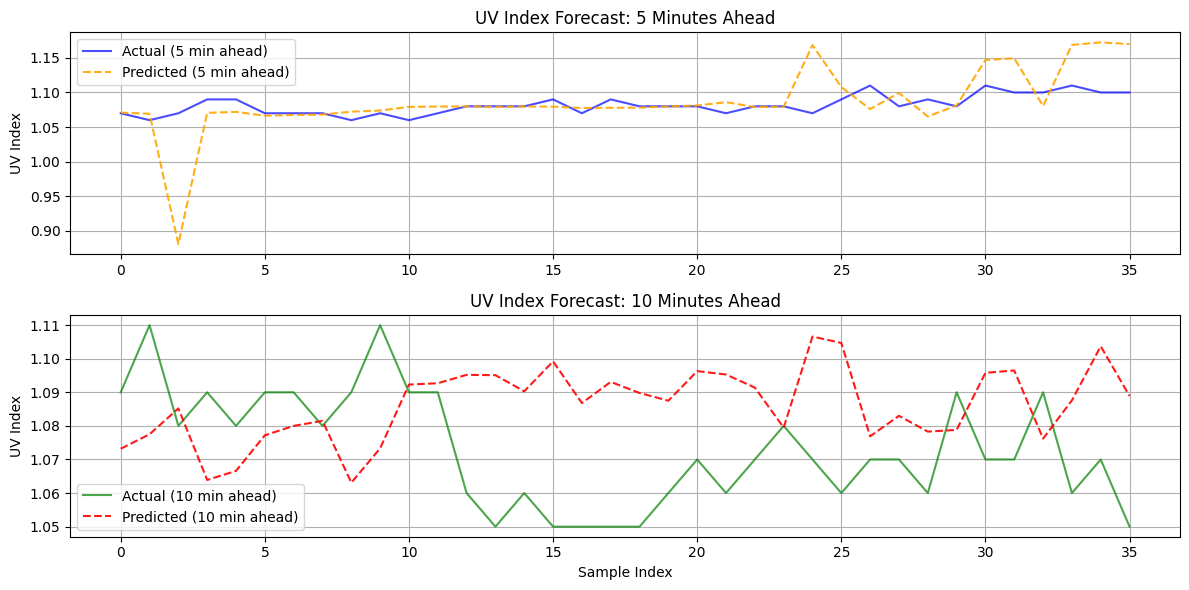

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt

# 1. Define future target shifts (5 minutes = 60 steps, 10 minutes = 120 steps)
steps_5min = 60
steps_10min = 120

df['Target_5min'] = df['UV_Index_Estimated'].shift(-steps_5min)
df['Target_10min'] = df['UV_Index_Estimated'].shift(-steps_10min)

# Drop rows with NaN targets at the end of the dataframe
df_model = df.dropna(subset=['Target_5min', 'Target_10min']).copy()

# 2. Select input features for prediction
features = ['Temperature_C', 'Humidity_percent', 'UV_RAW', 'UV_Voltage_V', 'UV_Index_Estimated']
X = df_model[features]

# --- Train Model for 5-Minute Horizon ---
y_5min = df_model['Target_5min']
X_train_5, X_test_5, y_train_5, y_test_5 = train_test_split(X, y_5min, test_size=0.2, shuffle=False)

model_5min = RandomForestRegressor(n_estimators=100, random_state=42)
model_5min.fit(X_train_5, y_train_5)
preds_5min = model_5min.predict(X_test_5)

print("--- 5-Minute Ahead Prediction ---")
print(f"MSE: {mean_squared_error(y_test_5, preds_5min):.4f}")
print(f"R² Score: {r2_score(y_test_5, preds_5min):.4f}\n")

# --- Train Model for 10-Minute Horizon ---
y_10min = df_model['Target_10min']
X_train_10, X_test_10, y_train_10, y_test_10 = train_test_split(X, y_10min, test_size=0.2, shuffle=False)

model_10min = RandomForestRegressor(n_estimators=100, random_state=42)
model_10min.fit(X_train_10, y_train_10)
preds_10min = model_10min.predict(X_test_10)

print("--- 10-Minute Ahead Prediction ---")
print(f"MSE: {mean_squared_error(y_test_10, preds_10min):.4f}")
print(f"R² Score: {r2_score(y_test_10, preds_10min):.4f}")

# 3. Plot the Forecasts
plt.figure(figsize=(12, 6))

plt.subplot(2, 1, 1)
plt.plot(y_test_5.values, label='Actual (5 min ahead)', color='blue', alpha=0.7)
plt.plot(preds_5min, label='Predicted (5 min ahead)', color='orange', linestyle='--', alpha=0.9)
plt.title('UV Index Forecast: 5 Minutes Ahead')
plt.ylabel('UV Index')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(y_test_10.values, label='Actual (10 min ahead)', color='green', alpha=0.7)
plt.plot(preds_10min, label='Predicted (10 min ahead)', color='red', linestyle='--', alpha=0.9)
plt.title('UV Index Forecast: 10 Minutes Ahead')
plt.xlabel('Sample Index')
plt.ylabel('UV Index')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

Improved 5-Min MSE: 0.0001


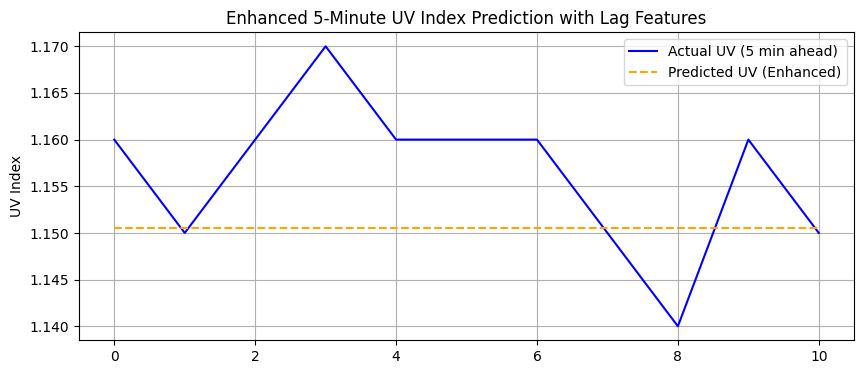

In [9]:
# 1. Add rolling and lag features to capture recent trends
df['UV_Lag1'] = df['UV_Index_Estimated'].shift(1)
df['UV_Lag2'] = df['UV_Index_Estimated'].shift(2)
df['UV_RollingMean5'] = df['UV_Index_Estimated'].rolling(5).mean()

# Drop rows with NaN from rolling/lag shifts
df = df.dropna().copy()

# 2. Redefine future targets (5 min = 60 steps ahead)
steps_5min = 60
steps_10min = 120

df['Target_5min'] = df['UV_Index_Estimated'].shift(-steps_5min)
df['Target_10min'] = df['UV_Index_Estimated'].shift(-steps_10min)
df_clean = df.dropna(subset=['Target_5min', 'Target_10min']).copy()

# 3. Updated feature set with history/momentum
features = [
    'Temperature_C', 'Humidity_percent', 'UV_RAW',
    'UV_Voltage_V', 'UV_Index_Estimated',
    'UV_Lag1', 'UV_Lag2', 'UV_RollingMean5'
]
X = df_clean[features]

# Train 5-minute model with new features
y_5min = df_clean['Target_5min']
X_train, X_test, y_train, y_test = train_test_split(X, y_5min, test_size=0.2, shuffle=False)

model_improved = RandomForestRegressor(n_estimators=150, random_state=42)
model_improved.fit(X_train, y_train)
preds_improved = model_improved.predict(X_test)

print(f"Improved 5-Min MSE: {mean_squared_error(y_test, preds_improved):.4f}")

# Plot comparison
plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:50], label='Actual UV (5 min ahead)', color='blue')
plt.plot(preds_improved[:50], label='Predicted UV (Enhanced)', color='orange', linestyle='--')
plt.title('Enhanced 5-Minute UV Index Prediction with Lag Features')
plt.ylabel('UV Index')
plt.legend()
plt.grid(True)
plt.show()

In [10]:
import joblib

# Save the trained Random Forest model to disk
model_filename = 'uv_model_5min.pkl'
joblib.dump(model_improved, model_filename)
print(f"Model successfully saved as {model_filename}")

# Optional: Download the file to your computer
from google.colab import files
files.download(model_filename)

Model successfully saved as uv_model_5min.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
import pandas as pd

# Upload or load the second dataset file
from google.colab import files
uploaded_new = files.upload()

# Get the filename
new_filename = list(uploaded_new.keys())[0] if uploaded_new else 'UV_Data_20261006_040353.xlsx'

# Load the Excel sheet into a pandas DataFrame
df_test = pd.read_excel(new_filename, sheet_name='UV_Data')
print(f"New dataset successfully loaded! Shape: {df_test.shape}")
display(df_test.head())

Saving UV_Data_20261006_040353.xlsx to UV_Data_20261006_040353 (1).xlsx
New dataset successfully loaded! Shape: (49, 10)


,Date,Time,Sample_Number,ESP32_Millis,Temperature_C,Humidity_percent,UV_RAW,UV_Voltage_V,UV_Intensity_mW_m2,UV_Index_Estimated
0,2026-10-06,04:03:59,1,5024,34.3,6,578,0.612,187.88,0.94
1,2026-10-06,04:04:04,2,10024,34.2,7,558,0.615,188.81,0.94
2,2026-10-06,04:04:09,3,15024,34.1,7,565,0.603,185.12,0.93
3,2026-10-06,04:04:14,4,20024,34.1,7,561,0.612,187.88,0.94
4,2026-10-06,04:04:19,5,25024,34.1,7,546,0.581,178.37,0.89


--- Test Predictions on New Dataset ---


,Time,Actual_UV,Predicted_UV
4,04:04:19,0.89,1.135267
5,04:04:24,0.92,1.135133
6,04:04:29,0.90,1.134867
7,04:04:34,0.91,1.135533
8,04:04:39,0.89,1.135067
9,04:04:44,0.92,1.134933
10,04:04:49,0.90,1.135267
11,04:04:54,0.92,1.135067
12,04:04:59,0.91,1.134800
13,04:05:04,0.90,1.135200


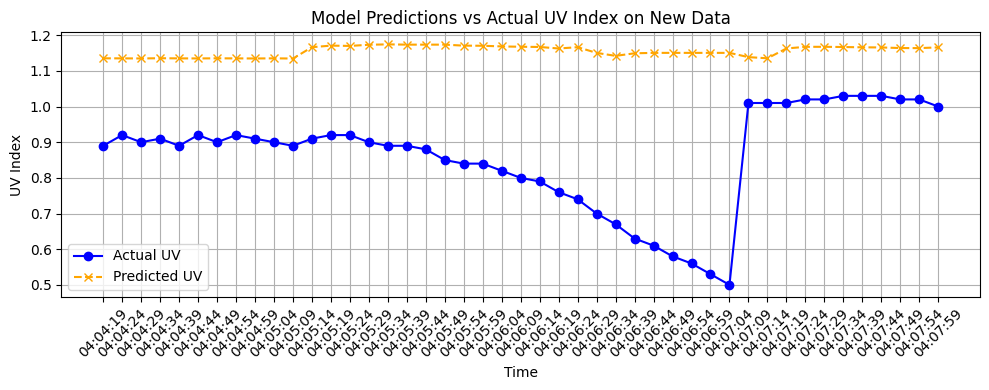

In [12]:
# 1. Apply feature engineering to the newly imported test dataset
df_test['UV_Lag1'] = df_test['UV_Index_Estimated'].shift(1)
df_test['UV_Lag2'] = df_test['UV_Index_Estimated'].shift(2)
df_test['UV_RollingMean5'] = df_test['UV_Index_Estimated'].rolling(5).mean()
df_test_clean = df_test.dropna().copy()

# 2. Extract features matching our trained model
features = [
    'Temperature_C', 'Humidity_percent', 'UV_RAW',
    'UV_Voltage_V', 'UV_Index_Estimated',
    'UV_Lag1', 'UV_Lag2', 'UV_RollingMean5'
]
X_new = df_test_clean[features]

# 3. Predict future UV index using our improved model
predicted_uv = model_improved.predict(X_new)

# 4. Display and compare actual vs predicted values
comparison_results = pd.DataFrame({
    'Time': df_test_clean['Time'],
    'Actual_UV': df_test_clean['UV_Index_Estimated'],
    'Predicted_UV': predicted_uv
})

print("--- Test Predictions on New Dataset ---")
display(comparison_results.head(10))

# 5. Plot the comparison
plt.figure(figsize=(10, 4))
plt.plot(comparison_results['Time'], comparison_results['Actual_UV'], label='Actual UV', color='blue', marker='o')
plt.plot(comparison_results['Time'], comparison_results['Predicted_UV'], label='Predicted UV', color='orange', linestyle='--', marker='x')
plt.title('Model Predictions vs Actual UV Index on New Data')
plt.xlabel('Time')
plt.ylabel('UV Index')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [13]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 1. Soma mafaili yote mawili
df1 = pd.read_excel('UV_Data_20261006_040916.xlsx', sheet_name='UV_Data')
df2 = pd.read_excel('UV_Data_20261006_040353.xlsx', sheet_name='UV_Data')

# 2. Unganisha pamoja ziwe dataset moja kubwa
combined_df = pd.concat([df1, df2], ignore_index=True)

# 3. Weka vipengele vya Lag na Rolling Means
combined_df['UV_Lag1'] = combined_df['UV_Index_Estimated'].shift(1)
combined_df['UV_Lag2'] = combined_df['UV_Index_Estimated'].shift(2)
combined_df['UV_RollingMean5'] = combined_df['UV_Index_Estimated'].rolling(5).mean()
combined_df = combined_df.dropna().copy()

# 4. Weka shabaha ya dakika 5 mbele (hatua 60)
combined_df['Target_5min'] = combined_df['UV_Index_Estimated'].shift(-60)
final_data = combined_df.dropna(subset=['Target_5min']).copy()

# 5. Gawanya kwa ajili ya kufundisha (Training & Testing)
features = ['Temperature_C', 'Humidity_percent', 'UV_RAW', 'UV_Voltage_V', 'UV_Index_Estimated', 'UV_Lag1', 'UV_Lag2', 'UV_RollingMean5']
X = final_data[features]
y = final_data['Target_5min']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=True)

# 6. Train model mpya iliyochanganywa
better_model = RandomForestRegressor(n_estimators=150, random_state=42)
better_model.fit(X_train, y_train)

preds = better_model.predict(X_test)
print(f"New Model MSE: {mean_squared_error(y_test, preds):.4f}")
print(f"New Model R² Score: {r2_score(y_test, preds):.4f}")

New Model MSE: 0.0053
New Model R² Score: 0.7274


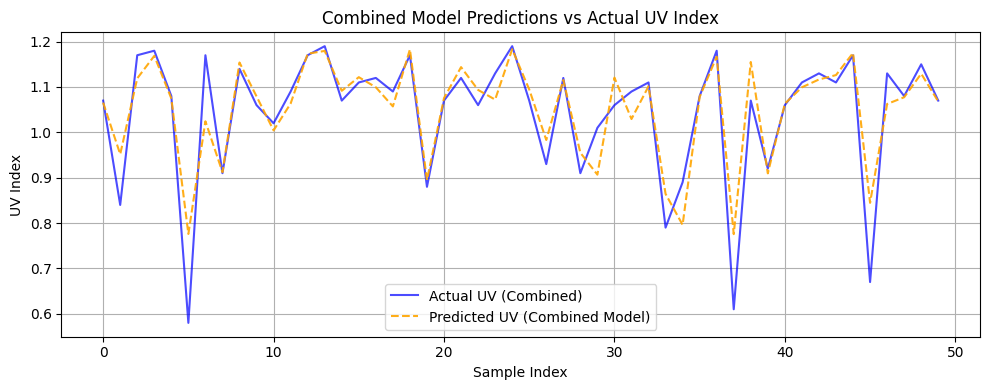

Modeli mpya imehifadhiwa kama uv_model_combined_5min.pkl!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
# 7. Kuchora graph ya kulinganisha Actual vs Predicted kwenye data zilizochanganywa
preds = better_model.predict(X_test)

plt.figure(figsize=(10, 4))
plt.plot(y_test.values[:50], label='Actual UV (Combined)', color='blue', alpha=0.7)
plt.plot(preds[:50], label='Predicted UV (Combined Model)', color='orange', linestyle='--', alpha=0.9)
plt.title('Combined Model Predictions vs Actual UV Index')
plt.xlabel('Sample Index')
plt.ylabel('UV Index')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Kuhifadhi hii modeli mpya iliyoboreshwa na kuipakua
import joblib
joblib.dump(better_model, 'uv_model_combined_5min.pkl')
print("Modeli mpya imehifadhiwa kama uv_model_combined_5min.pkl!")

from google.colab import files
files.download('uv_model_combined_5min.pkl')

In [ ]:
acorni